In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!pip install ultralytics -q

ERROR: Could not find a version that satisfies the requirement ultralytics (from versions: none)
ERROR: No matching distribution found for ultralytics


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch

from ultralytics import YOLO

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

In [3]:
import importlib.util

print("PyTorch:", importlib.util.find_spec("torch") is not None)
print("OpenCV:", importlib.util.find_spec("cv2") is not None)
print("Ultralytics:", importlib.util.find_spec("ultralytics") is not None)

PyTorch: True
OpenCV: True
Ultralytics: False


In [4]:
import torchvision
from pathlib import Path

print("Torchvision version:", torchvision.__version__)

print("\nAvailable datasets:")
print(list(Path("/kaggle/input").iterdir()))

Torchvision version: 0.26.0+cpu

Available datasets:
[]


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Files:", files[:10])

Folder: /kaggle/input
Files: []
Folder: /kaggle/input/notebooks
Files: []
Folder: /kaggle/input/notebooks/sudhanshu2198
Files: []
Folder: /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection
Files: ['1.png', '__notebook__.ipynb', '__output__.json', '__results__.html', '__resultx__.html', 'custom.css', 'yolo.yaml', 'yolov8m.pt', 'yolov8n.pt']
Folder: /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/__results___files
Files: ['__results___26_0.png']
Folder: /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data
Files: []
Folder: /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data/images
Files: []
Folder: /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data/images/train
Files: ['vid_4_1000.jpg', 'vid_4_10000.jpg', 'vid_4_10060.jpg', 'vid_4_10080.jpg', 'vid_4_10120.jpg', 'vid_4_10140.jpg', 'vid_4_10180.jpg', 'vid_4_10200.jpg', 'vid_4_10220.jpg', 'vid_4_10240.jpg']
Folder: /kaggle/input/notebooks/sudhanshu2198

In [6]:
from pathlib import Path

BASE = Path("/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection")

print("Dataset configuration:")
print((BASE / "yolo.yaml").read_text())

print("\nTraining images:",
      len(list((BASE / "data/images/train").glob("*"))))

print("Validation images:",
      len(list((BASE / "data/images/val").glob("*"))))

print("\nTraining labels:",
      len(list((BASE / "data/labels/train").glob("*.txt"))))

Dataset configuration:
names:
  0: car
nc: 1
path: /kaggle/working/data
train: /kaggle/working/data/images/train
val: /kaggle/working/data/images/val


Training images: 800
Validation images: 201

Training labels: 281


In [1]:
import os

print(os.listdir("/kaggle/input"))

['notebooks']


In [2]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

image_path = next(Path("/kaggle/working/data/images/train").glob("*.jpg"))

image = Image.open(image_path)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Image:", image_path.name)

StopIteration: 

In [3]:
from pathlib import Path

train_dir = Path("/kaggle/working/data/images/train")

image_files = [
    p for p in train_dir.glob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Images found:", len(image_files))
print("First image:", image_files[0] if image_files else "None found")

Images found: 0
First image: None found


In [4]:
from pathlib import Path

for folder in [Path("/kaggle/input"), Path("/kaggle/working")]:
    print("\nSearching:", folder)

    found = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print("Images found:", len(found))

    for img in found[:5]:
        print(img)


Searching: /kaggle/input
Images found: 1059
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/1.png
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/__results___files/__results___26_0.png
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/wandb/run-20230815_064419-u4a8wirl/files/media/images/F1_curve_17_3bbe5235dfa786b9dbc0.png
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/wandb/run-20230815_064419-u4a8wirl/files/media/images/F1_curve_17_5aec51a81f81a1a33f4e.png
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/wandb/run-20230815_064419-u4a8wirl/files/media/images/PR_curve_17_ed8e94ae3cd7e38ebc80.png

Searching: /kaggle/working
Images found: 0


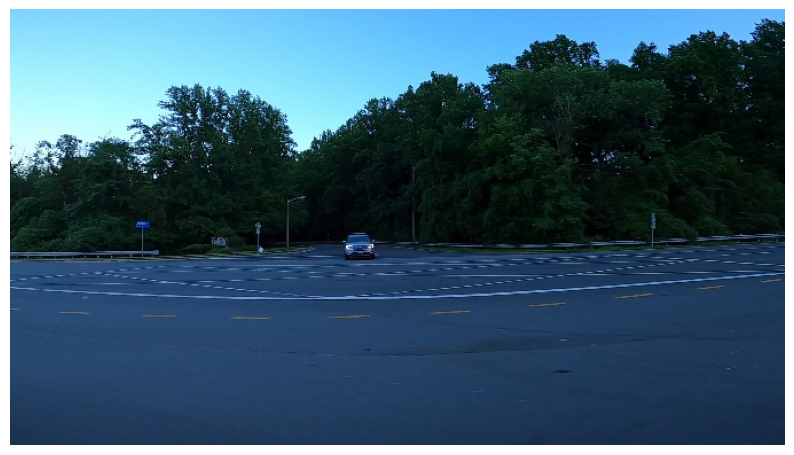

In [5]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

train_dir = Path(
    "/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data/images/train"
)

image_path = next(
    p for p in train_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

image = Image.open(image_path)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [7]:
import urllib.request

try:
    urllib.request.urlopen("https://pypi.org", timeout=10)
    print("Internet connection is working!")
except Exception as e:
    print("Internet connection failed:", e)

KeyboardInterrupt: 

In [8]:
import urllib.request

try:
    urllib.request.urlopen("https://pypi.org", timeout=10)
    print("Internet connection is working!")
except Exception as e:
    print("Internet connection failed:", e)

KeyboardInterrupt: 

In [9]:
from pathlib import Path

project_dir = Path("/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection")

for file in project_dir.glob("*.pt"):
    print(file)

/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/yolov8m.pt
/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/yolov8n.pt


In [10]:
label_dir = Path(
    "/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data/labels/train"
)

label_path = label_dir / f"{image_path.stem}.txt"

print("Label file:", label_path.name)
print("Annotation:", label_path.read_text())

Label file: vid_4_1000.txt
Annotation: 0.0 0.45043415340236687 0.539816602368421 0.06874095502958583 0.09523809526315791



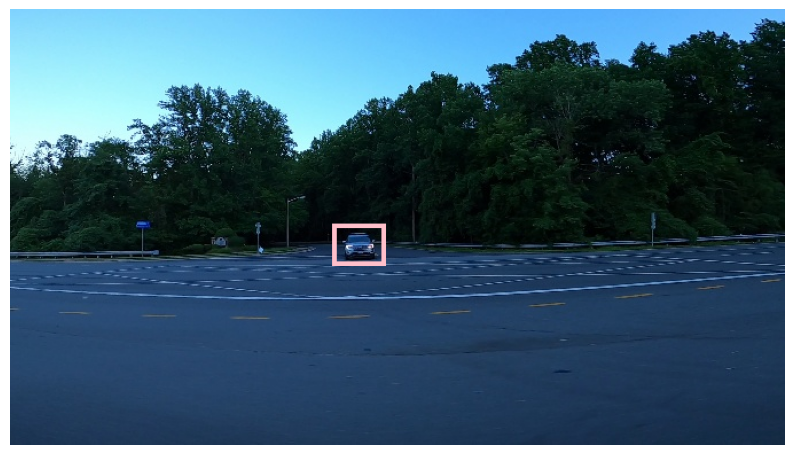

In [17]:
from PIL import ImageDraw

# Open the image
image = Image.open(image_path).convert("RGB")

# Read annotation values
values = label_path.read_text().split()

class_id = int(float(values[0]))
x_center, y_center, box_width, box_height = map(float, values[1:])

# Get image dimensions
img_width, img_height = image.size

# Convert normalized coordinates into pixels
x_center *= img_width
y_center *= img_height
box_width *= img_width
box_height *= img_height

# Calculate rectangle corners
x1 = x_center - box_width / 2
y1 = y_center - box_height / 2
x2 = x_center + box_width / 2
y2 = y_center + box_height / 2

# Draw the rectangle
draw = ImageDraw.Draw(image)
draw.rectangle([x1, y1, x2, y2], outline="pink", width=4)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [13]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics] [ultralytics]platform]


In [14]:
from ultralytics import YOLO

model_path = "/kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/yolov8n.pt"

model = YOLO(model_path)

print("YOLO model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!


In [15]:
results = model.predict(
    source=str(image_path),
    conf=0.25,
    save=True
)

print("Prediction completed!")


image 1/1 /kaggle/input/notebooks/sudhanshu2198/yolov8-car-object-detection/data/images/train/vid_4_1000.jpg: 384x640 2 cars, 480.4ms
Speed: 29.1ms preprocess, 480.4ms inference, 56.9ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /kaggle/working/runs/detect/predict
Prediction completed!


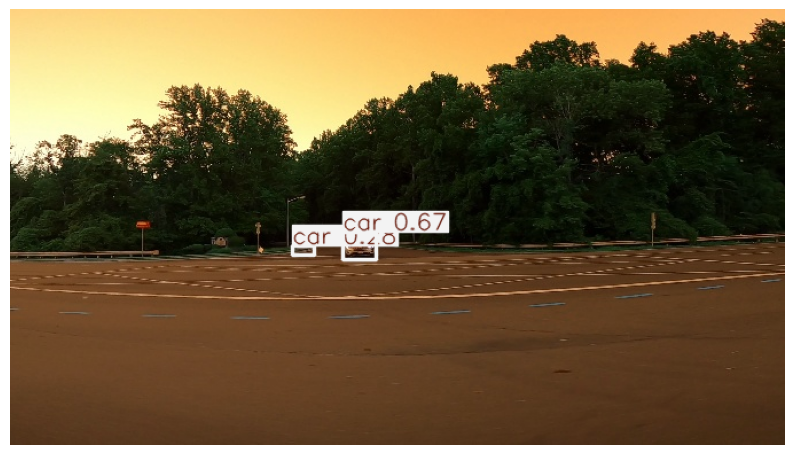

In [16]:
result_image = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(result_image)
plt.axis("off")
plt.show()

In [19]:
results[0].boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([2., 2.])
conf: tensor([0.6698, 0.2781])
data: tensor([[2.9084e+02, 1.9437e+02, 3.1944e+02, 2.1875e+02, 6.6975e-01, 2.0000e+00],
        [2.4629e+02, 2.0610e+02, 2.6547e+02, 2.1484e+02, 2.7808e-01, 2.0000e+00]])
id: None
is_track: False
orig_shape: (380, 676)
shape: torch.Size([2, 6])
xywh: tensor([[305.1365, 206.5602,  28.5990,  24.3827],
        [255.8793, 210.4696,  19.1740,   8.7389]])
xywhn: tensor([[0.4514, 0.5436, 0.0423, 0.0642],
        [0.3785, 0.5539, 0.0284, 0.0230]])
xyxy: tensor([[290.8370, 194.3689, 319.4360, 218.7515],
        [246.2924, 206.1002, 265.4663, 214.8391]])
xyxyn: tensor([[0.4302, 0.5115, 0.4725, 0.5757],
        [0.3643, 0.5424, 0.3927, 0.5654]])

In [20]:
results[0].boxes.conf

tensor([0.6698, 0.2781])

In [23]:
results[0].boxes.cls

tensor([2., 2.])